<a href="https://colab.research.google.com/github/CluelessXftw/CluelessXftw/blob/main/Machine_Learning_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### LIBRARIES IMPORT, PLEASE PRESS THIS BEFORE RUNNING ANYTHING

In [ ]:
import numpy as np
from numpy.linalg import inv, det, pinv
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn import tree
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import math
from scipy import stats
import sympy as sp

### Probability Stuff

In [ ]:
from scipy import stats

# define constants mu =
30    # mean = 30Ω
sigma = 1.8  # standard deviation = 1.8Ω
x1 = 28      # lower bound = 28Ω x2 = 33
# upper bound = 33Ω

## calculate probabilities
# probability from Z=0 to lower bound
p_lower = stats.norm.cdf(x1,mu,sigma) #
probability from Z=0 to upper bound
p_upper = stats.norm.cdf(x2,mu,sigma)
# probability of the interval
Prob = (p_upper) - (p_lower)

# print the results print('\n')
print(f'Normal distribution: mean = {mu}, std dev = {sigma} \n')
print(f'Probability of occurring between {x1} and {x2}: ')
print(f'--> inside interval Pin = {round(Prob*100,1)}%') print(f'-
-> outside interval Pout = {round((1-Prob)*100,1)}% \n')
print('\n')

SyntaxError: invalid syntax (1141781530.py, line 12)

### Solving for Linear Equation
𝐰̂ = (𝐗^−1).𝐲

In [ ]:
X = np.array([[1, 1], [3, 4]]) #CHANGE THIS


#DONT TOUCH BELOW

inv_X = np.linalg.inv(X)
y = np.array([0, 1])
w = inv_X.dot(y)
print(w)

[-1.  1.]


### GENERAL MATRIX

In [ ]:
# DEFINE YOUR MATRIX HERE
A = np.array([[1,2,3,4],[2.5,5,6,8],[3,6,9,12],[4,8,12,16],[5,10,15,20]])


# DONT TOUCH BELOW


# calculates the rank of a given matrix
def rankofmatrix(X):
  X = np.array(X)
  return np.linalg.matrix_rank(X)
#print(rankofmatrix([[1,2,3],[4,5,6],[7,8,9]]))


#Checks if a given square matrix X is invertible.
def invertible(X): # Works only for square matrix
  X = np.array(X)
  return True if np.shape(X)[0]==np.shape(X)[1] and np.round(np.linalg.det(X),decimals = 5)!=0 else False
#print(invertible([[1,2],[3,6]]))


#Checks if a matrix X is left-invertible
def left_invertible(X):
  X = np.array(X)
  XT = np.transpose(X)
  return invertible(np.dot(XT,X))
print(left_invertible(A))


#Checks if a matrix X is right-invertible
def right_invertible(X):
  X = np.array(X)
  XT = np.transpose(X)
  return invertible(np.dot(X,XT))
#print(right_invertible([[1,4,3],[2,-1,3]]))


## These 2 functions is to determine the linear dependency of rows and columns
def each_row_independent(X):
  X = np.array(X)
  if np.shape(X)[0]<np.shape(X)[1]:
    return right_invertible(X)
  elif np.shape(X)[0]==np.shape(X)[1]:
    return invertible(X)
  else:
    return True if np.linalg.matrix_rank(X)==np.shape(X)[1] else False
#print(each_row_independent([[1,2,3],[2,4,6]]))


def each_column_independent(X):
  X = np.array(X)
  if np.shape(X)[1]<np.shape(X)[0]:
    return left_invertible(X)
  elif np.shape(X)[0]==np.shape(X)[1]:
    return invertible(X)
  else:
    return True if np.linalg.matrix_rank(X)==np.shape(X)[0] else False
  #print(each_row_independent([[1,2,3],[2,4,6]]))

def check_determinant(matrix):
    matrix = np.array(matrix)
    rows, cols = matrix.shape

    if rows != cols:
        print("Matrix is not square. It has no determinant.")
        return None
    else:
        det = np.linalg.det(matrix)
        print(f"Matrix is square ({rows}x{cols}). Determinant = {det:.4f}")
        return det
    #print(check_determinant(A))

False


NORMAL DISTRIBUTION

In [ ]:
# define constants
mu = 30 # Mean
sigma = 1.8 # Standard Deviation
x1 = 28 # lower bound = 28Ω
x2 = 33 # upper bound = 33Ω

## calculate probabilities
# probability from Z=0 to lower bound
p_lower = stats.norm.cdf(x1,mu,sigma) #probability from Z=0 to upper bound
p_upper = stats.norm.cdf(x2,mu,sigma)

# probability of the interval
Prob = (p_upper) - (p_lower)

##print the results print('\n'); uncomment all below if needed
#print(f'Normal distribution: mean = {mu}, std dev = {sigma} \n')
#print(f'Probability of occurring between {x1} and {x2}: ')
#print(f'--> inside interval Pin = {round(Prob*100,1)}%')
#print(f'--> outside interval Pout = {round((1-Prob)*100,1)}% \n')
#print('\n')

### DICE PROBABILITY

In [ ]:
#(i)  List out all pairs of possible outcomes together with their sums from the two throws of 6-sided dice
d={(i,j):i+j for i in range(1,7) for j in range(1,7)}
#print(d)
#print("\n")

# (ii) Collect all of the (a, b) pairs that sum to each of the possible values from two to twelve (including the sum equals seven)
from collections import defaultdict
dinv = defaultdict(list)
for i,j in d.items(): dinv[j].append(i)
#print(dinv)

#calculates the probability of rolling each sum
X={i:len(j)/36. for i,j in dinv.items() }
#print(X)

#Lists out all the sum permutations
sumProb = 0
for x in X.keys():
    if (x > 2 & x < 12):
        sumProb += X.get(x)
#print(sumProb)
#print("\n")

# (b) What is the probability that half the product of three dice will exceed their sum?
d={(i,j,k):((i*j*k)/2>i+j+k) for i in range(1,7)
    for j in range(1,7)
        for k in range(1,7)}

#counting successful outcomes
dinv = defaultdict(list)
for i,j in d.items(): dinv[j].append(i)
X={i:len(j)/6.0**3 for i,j in dinv.items() }
#print(X)

### LINEAR REGRESSION COMBINED, no bias; goes through origin, controlled experiments, math models
The code determines if the system is over-, under-, or evenly determined.
It computes weights 𝑤 using different matrix inversion techniques.
Predicts new outputs 𝑦pred
Evaluates performance using MSE.

#### For Xw = y; general Linear Regression question unless differently stated

In [ ]:
X = np.array([[1,4],[2,7],[-3,11]])  # CHANGE THIS
y = np.array([1,-2.5,4])            # CHANGE THIS
x_test = np.array([[-1, 2, 8], [1, 5, -1]])  # Test data; CHANGE ACCORDINGLY


#DONT TOUCH BELOW



#Full code to check system: is invertible? what determine? and the weights
def check_system(X, y):
    # If X is 1D, reshape it to a 2D column vector (m, 1)
    if len(X.shape) == 1:
        X = X.reshape(-1, 1)  # Reshape to column vector

    m, n = X.shape  # Get dimensions (m = rows, n = columns)

    print(f"Shape of X: {X.shape}, Shape of y: {y.shape}")

    X = np.array(X)
    print("Is invertible" if np.shape(X)[0]==np.shape(X)[1] and np.round(np.linalg.det(X),decimals = 5)!=0 else "is not invertible")

    if m > n:  # Over-determined (More equations than parameters)
        print("System is OVER-DETERMINED (m > n). Using Least Squares. NO EXACT SOLUTION. Only left-invertible.")
        w = inv(X.T @ X) @ X.T @ y if det(X.T @ X) != 0 else pinv(X) @ y

    elif m == n:  # Even-determined (Square system)
        print("System is EVEN-DETERMINED (m = n). Exact solution, no solution or infinite solutions. Can be both left or right invertible")

        if det(X) != 0:
            print("Matrix is invertible. Using direct inversion.")
            w = inv(X) @ y
        else:
            print("Matrix is singular. Using pseudo-inverse.")
            w = pinv(X) @ y

    else:  # Under-determined (More parameters than equations)
        print("System is UNDER-DETERMINED (m < n). Using Pseudo-Inverse. Only infinite solutions. Right-invertible.")
        w = pinv(X) @ y

    print("Computed weights (w), is a column vector: ")
    print(w)
    return w #w is typically a column vector!!!

# Get weights
w = check_system(X, y)

#For prediction
y_pred_linear = x_test @ w
print(f"y_prediction_linear_notBias IS COLUMN VECTOR:\n {y_pred_linear}\n")

Shape of X: (3, 2), Shape of y: (3,)
is not invertible
System is OVER-DETERMINED (m > n). Using Least Squares. NO EXACT SOLUTION. Only left-invertible.
Computed weights (w), is a column vector: 
[-1.05863808  0.07860446]


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)

#### For W^T.X = y

In [ ]:
# Matrix and vector
X = np.array([[1, 2], [2, 4], [1, -1]])  # CHANGE THIS
y = np.array([[0], [1]])                # CHANGE THIS
x_test = np.array([[-1, 2, 8], [1, 5, -1]])  # Test data; CHANGE ACCORDINGLY


# DONT TOUCH BELOW



# Transpose X to get X^T
X_T = X.T  # Shape: (2 x 3)

# Get the shape of X^T for system type check
equations, unknowns = X_T.shape

# Determine the system type
if equations > unknowns:
    system_type = "Over-determined"
elif equations < unknowns:
    system_type = "Under-determined"
else:
    system_type = "Even-determined"

print(f"System type: {system_type}")

# Check rank of X^T
rank = np.linalg.matrix_rank(X_T)
print(f"Rank of X^T: {rank}")

# Solve X^T w = y using least squares
w_solution, residuals, _, _ = np.linalg.lstsq(X_T, y, rcond=None)

print("\nSolution for w:")
print(w_solution)

# Check if the solution is exact
if residuals.size > 0 and np.allclose(residuals, 0, atol=1e-8):
    print("\nThe solution is an exact fit.")
else:
    print("\nThe solution is a least-squares approximation.")

# Ensure w is a column vector
if w_solution.ndim == 1:
    w_solution = w_solution.reshape(-1, 1)
elif w_solution.shape[0] < w_solution.shape[1]:
    w_solution = w_solution.T


#For prediction
y_pred_linear = x_test @ w_solution
print(f"y_prediction_linear_notBias IS COLUMN VECTOR:\n {y_pred_linear}\n")

System type: Under-determined
Rank of X^T: 2

Solution for w:
[[ 0.06666667]
 [ 0.13333333]
 [-0.33333333]]

The solution is a least-squares approximation.
y_prediction_linear_notBias IS COLUMN VECTOR:
 [[-2.46666667]
 [ 1.06666667]]



#### Data testing with and without regularization
Plot included

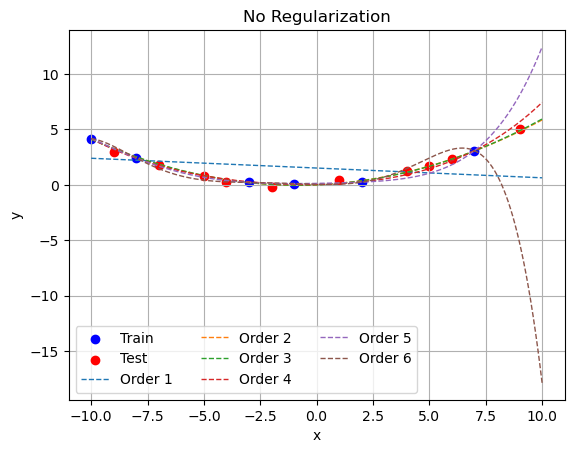

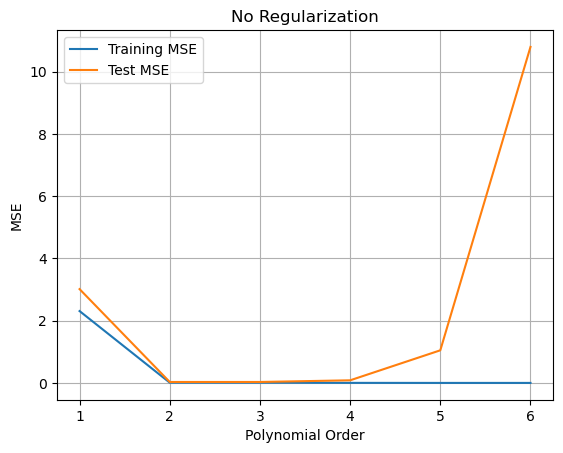

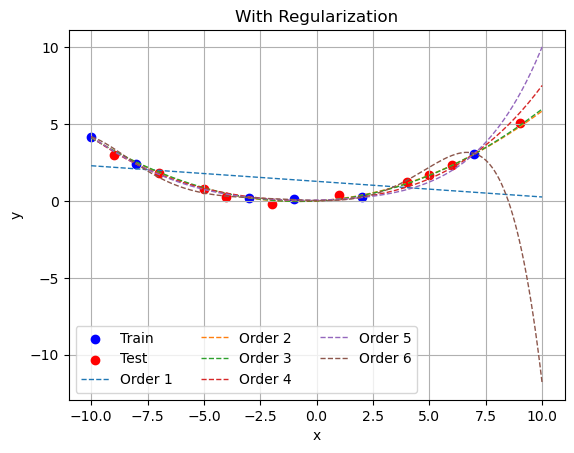

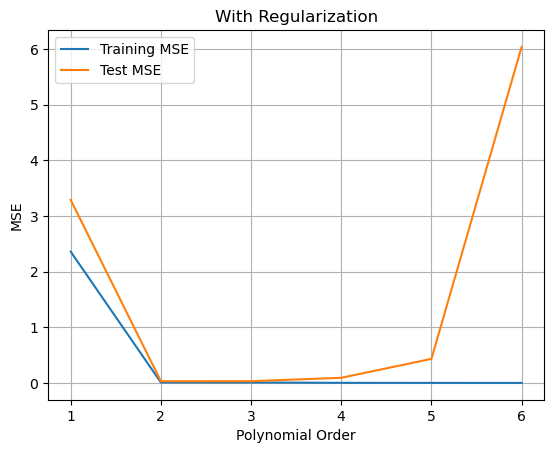

In [ ]:
# training data
X = np.array([[-10],[-8],[-3],[-1],[2],[7]])
y = np.array([[4.18],[2.42],[0.22],[0.12],[0.25],[3.091]])

# test data
x_test = np.array([[-9],[-7],[-5],[-4],[-2],[1],[4],[5],[6],[9]])
yt = np.array([[3],[1.81],[0.80],[0.25],[-0.19],[0.4],[1.24],[1.68],[2.32],[5.065]])

max_order = 6
regularization_lambda = 1

# Ensure data is in column vector form
X = X.reshape(-1, 1)
y = y.reshape(-1, 1)
x_test = x_test.reshape(-1, 1)
yt = yt.reshape(-1, 1)

def solvePR(P, y, ridge=False, lamb=0.01):
    if ridge:
        if P.shape[0] > P.shape[1]:  # Primal
            w = inv(P.T @ P + lamb * np.identity(P.shape[1])) @ P.T @ y
        else:  # Dual
            w = P.T @ inv(P @ P.T + lamb * np.identity(P.shape[0])) @ y
    else:
        if P.shape[0] > P.shape[1]:  # Primal
            w = inv(P.T @ P) @ P.T @ y
        else:  # Dual
            w = P.T @ inv(P @ P.T) @ y
    return w

def plot_mse(train_mse_lst, test_mse_lst, reg):
    plt.figure()
    plt.plot(np.linspace(1, max_order, max_order), train_mse_lst, label='Training MSE')
    plt.plot(np.linspace(1, max_order, max_order), test_mse_lst, label='Test MSE')
    plt.xlabel('Polynomial Order')
    plt.ylabel('MSE')
    plt.title('With Regularization' if reg else 'No Regularization')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_poly(w_lst, Poly_lst, reg):
    x_plot = np.linspace(-10, 10, 200).reshape(-1, 1)
    plt.figure()
    plt.scatter(X, y, color='blue', label='Train')
    plt.scatter(x_test, yt, color='red', label='Test')

    for i in range(len(w_lst)):
        P_plot = Poly_lst[i].fit_transform(x_plot)
        y_plot_pred = P_plot @ w_lst[i]
        plt.plot(x_plot, y_plot_pred, linestyle='--', linewidth=1, label=f'Order {i+1}')

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('With Regularization' if reg else 'No Regularization')
    plt.legend(loc='lower left', ncol=3)
    plt.grid(True)
    plt.show()

# ----- (a) No Regularization -----
w_lst_noReg = []
Poly_lst_noReg = []
train_mse_lst_noReg = []
test_mse_lst_noReg = []

for order in range(1, max_order+1):
    poly = PolynomialFeatures(order)
    P_train = poly.fit_transform(X)
    P_test = poly.fit_transform(x_test)
    Poly_lst_noReg.append(poly)

    w = solvePR(P_train, y)
    w_lst_noReg.append(w)

    y_train_pred = P_train @ w
    y_test_pred = P_test @ w

    train_mse = np.mean((y_train_pred - y) ** 2)
    test_mse = np.mean((y_test_pred - yt) ** 2)

    train_mse_lst_noReg.append(train_mse)
    test_mse_lst_noReg.append(test_mse)

plot_poly(w_lst_noReg, Poly_lst_noReg, False)
plot_mse(train_mse_lst_noReg, test_mse_lst_noReg, False)

# ----- (b) With Regularization -----
w_lst_reg = []
Poly_lst_reg = []
train_mse_lst_reg = []
test_mse_lst_reg = []

for order in range(1, max_order+1):
    poly = PolynomialFeatures(order)
    P_train = poly.fit_transform(X)
    P_test = poly.fit_transform(x_test)
    Poly_lst_reg.append(poly)

    w = solvePR(P_train, y, ridge=True, lamb=regularization_lambda)
    w_lst_reg.append(w)

    y_train_pred = P_train @ w
    y_test_pred = P_test @ w

    train_mse = np.mean((y_train_pred - y) ** 2)
    test_mse = np.mean((y_test_pred - yt) ** 2)

    train_mse_lst_reg.append(train_mse)
    test_mse_lst_reg.append(test_mse)

plot_poly(w_lst_reg, Poly_lst_reg, True)
plot_mse(train_mse_lst_reg, test_mse_lst_reg, True)


### LINEAR REGRESSION, with BIAS/OffSet; using real life data, does not go through origin

In [ ]:
X = np.array([[1,0,1,0],[1,-1,1,-1],[1,1,0,0]]) #CHANGE THIS
y = np.array([1,0,1]) #CHANGE THIS

x_test = np.array([8,0,0,8])  #  CHANGE HERE; for prediction else ignore

# DONT TOUCH BELOW

dim = np.shape(X)
X = np.c_[np.ones((dim[0], 1)),X] #add bias. np.ones(m, 1) where m is how many entries.

if x_test.ndim == 1:
    x_test = x_test.reshape(1, -1)  # Convert to 2D row vector


#Check for dimensions
#To find w from X and y

dim = np.shape(X)

if dim[0] > dim[1]: #More rows than columns, over-determined system
    #w = inv(XT*X) * XT * y
    w = inv(X.T@X) @X.T @ y
    print("Over-determined")

elif dim[0] == dim[1]:
    #w = inv(X) * y
    w = inv(X) @ y
    print("Even-determined")

elif dim[0] < dim[1]:
    #w = XT * int(X*XT) * y
    w = X.T @ inv(X@ X.T) @ y
    print("Under-determined")
else:
    print("Not possible, please proceed to ridge regression")

print("weights for each parameter: ")
print(w)

x_test = np.c_[np.ones((x_test.shape[0], 1)), x_test]  # Add bias term (ones) to x_test

# To predict y, after finding X and w
# Predictions for new data (assuming no bias term is added)
# Make predictions using the computed weights
y_pred_linear = x_test @ w
print(f"y_prediction_linear_bias:\n {y_pred_linear}\n")

LinAlgError: Singular matrix

### RIDGE REGRESSION (regularization), NO BIAS, NO POLYNOMIAL
enhances linear regression by incorporating Ridge Regression (L2 regularization) to handle cases where the system is not invertible or poorly conditioned;

prevents overfitting; can be applied to multi-target regression

In [ ]:
X = np.array([[1,0,1,0],[1,-1,1,-1],[1,1,0,0]]) #CHANGE
y = np.array([1,0,1]) #CHANGE

x_test = np.array([1,0,1,0]) #CHANGE

#estimates the weights w based on the structure of X and whether regularization is applied.
def estimate_weights(X, y, reg=None):
    if reg == None: # least square

        if X.shape[0] > X.shape[1]: # m>d
            print("Primal form / over-determined")
            w = inv(X.T @ X) @ X.T @ y # Primal form
        else: #d>m
            print("Dual form / even or under-determined")
            w = X.T @ inv(X @ X.T) @ y # Dual form

    else:
        if X.shape[0] > X.shape[1]: # m>d
            w = inv(X.T @ X + reg*np.eye(X.shape[1])) @ X.T @ y # primal
            print("Primal form / over-determined")

        else: #d>m
            print("Dual form / even or under-determined")
            w = X.T @ inv(X @ X.T + reg*np.eye(X.shape[0])) @ y # dual

    return w

w = estimate_weights(X,y,0.001) #Edit ridge coefficient here

#DONT TOUCH BELOW




def mse(y,y_est): # x is a vector
    mse = np.mean((y - y_est)**2)
    return mse

print("weights for each parameter: ")
print(w)


if x_test.any() and w.any():

    res = x_test @ w
    print()
    print("y_pred: ")
    print(res)

MSE = True

if MSE :
    y_est = X@w
    res = []
    for j in range(y.size):
        res.append(mse(y[j],y_est[j]))
    print()
    print("MSE: ")
    print(sum(res)/len(res))


Dual form / even or under-determined
weights for each parameter: 
[0.50012403 0.49987472 0.49887846 0.49862914]

y_pred: 
0.9990024923987695

MSE: 
4.145513295173128e-07


### Polynomial Regression with or without Ridge Regression

In [ ]:
x = np.array([[1,3],[4,-1],[3,3]]) #CHANGE
y = np.array([[1],[2],[1]]) #CHANGE
polynomial_order = 3 #CHANGE AS QUESTION
x_test = np.array([0])  # CHANGE


#DONT TOUCH BELOW
# Count number of parameters
poly = PolynomialFeatures(polynomial_order)
P = poly.fit_transform(x)
num_parameters = P.shape[1]
print(f"Number of parameters to learn (polynomial features): {num_parameters}\n")

def polyTx(X, order):
    poly = PolynomialFeatures(order)
    P = poly.fit_transform(X)

    return P

def biasTx(X):
    bias = PolynomialFeatures(1)
    bias_X = bias.fit_transform(X)

    return bias_X

def solvePR(P, y, ridge=False, lamb=0.01):
    if ridge:
        if P.shape[0] > P.shape[1]:  # Primal Ridge Regressional
            print(f"NOTICE: Using Primal Ridge with lambda={lamb}\n\n")
            w = inv(P.T @ P + lamb * np.identity(np.shape(P)[1])) @ P.T @ y
        else:  # Dual
            print(f"NOTICE: Using Dual Ridge with lambda={lamb}\n\n")
            w = P.T @ inv(P @ P.T + lamb * np.identity(np.shape(P)[0])) @ y
    else:
        if P.shape[0] > P.shape[1]:  # Primal
            print(f"NOTICE: Using Primal Polynomial\n\n")
            w = inv(P.T @ P) @ P.T @ y
        else:  # Dual
            print(f"NOTICE: Using Dual Polynomial\n\n")
            w = P.T @ inv(P @ P.T) @ y

    return w


# Generate polynomial features
P = polyTx(x, polynomial_order)
print(f"Polynomial:\n {P}\n")

# Polynomial regression
w_poly = solvePR(P, y, ridge=False)
# w_poly = np.around(w_poly, decimals=5)
print(f"w_dual(No ridge):\n {w_poly.reshape(-1,1)}\n")

# Ridge regression, if needed
w_ridge = solvePR(P, y, ridge=True, lamb=0.0001)
# w_ridge = np.around(w_poly, decimals=5)
print(f"w_ridge:\n {w_ridge.reshape(-1,1)}\n")

Number of parameters to learn (polynomial features): 10

Polynomial:
 [[  1.   1.   3.   1.   3.   9.   1.   3.   9.  27.]
 [  1.   4.  -1.  16.  -4.   1.  64. -16.   4.  -1.]
 [  1.   3.   3.   9.   9.   9.  27.  27.  27.  27.]]

NOTICE: Using Dual Polynomial


w_dual(No ridge):
 [[ 0.00198111]
 [ 0.00237796]
 [ 0.00325314]
 [ 0.00558615]
 [-0.00362696]
 [ 0.01244962]
 [ 0.02328133]
 [-0.02628489]
 [-0.00012004]
 [ 0.03465864]]

NOTICE: Using Dual Ridge with lambda=0.0001


w_ridge:
 [[ 0.00198111]
 [ 0.00237796]
 [ 0.00325314]
 [ 0.00558615]
 [-0.00362695]
 [ 0.01244961]
 [ 0.02328133]
 [-0.02628488]
 [-0.00012003]
 [ 0.03465863]]



In [ ]:
def estimate_weights(P, y, reg=None):
    if reg == None: # least square

        if P.shape[0] > P.shape[1]: # m>d
            print("Primal form / over-determined")
            w = inv(P.T @ P) @ P.T @ y # Primal form
        else: #d>m
            print("Dual form / under-determined")
            w = P.T @ inv(P @ P.T) @ y # Dual form

    else:
        if P.shape[0] > P.shape[1]: # m>d
            w = inv(P.T @ P + reg*np.eye(P.shape[1])) @ P.T @ y # primal
        else: #d>m
            w = P.T @ inv(P @ P.T + reg*np.eye(P.shape[0])) @ y # dual

    return w

def mse(y,y_est): # x is a vector
    mse = np.mean((y - y_est)**2)
    return mse

X_train = np.array([[-10,90],[-8,9],[-3,7],[-1,1],[2,19,],[8,20]]) # Do not need to add bias
y_train = np.array([5,5,4,3,2,2])

order = 4 #Polynomial order. Put to 1 for linear regression with bias.
poly = PolynomialFeatures(order)
P_train = poly.fit_transform(X_train)
print("Number of parameters to learn for this order")
print(len(P_train[0]))

X_test = [[9,19]] # Do not need to add bias
P_test = poly.fit_transform(X_test)

# y_test = P_test @ w

print("weights for each parameter: ")
w = estimate_weights(P_train, y_train, reg=None)
print(w)

print()
print("y_pred = ", P_test @ w ) # from definition above

MSE = True

if MSE :
    y_est = P_train@w
    res = []
    for j in range(y_train.size):
        res.append(mse(y_train[j],y_est[j]))
    print()
    print("MSE: ")
    print(sum(res)/len(res))


Number of parameters to learn for this order
15
weights for each parameter: 
Dual form / under-determined
[ 0.3968004  -0.3947137   0.39051822  0.38648095 -0.37581527  0.33906842
 -0.34081976  0.31605815 -0.24689615 -0.10094436  0.11544971  0.09745184
 -0.08739608  0.02108656  0.00425811]

y_pred =  [245.45919661]

MSE: 
1.8930725747534957e-16


### Multi-Polynomial regression to find the best order

In [ ]:
X_train = np.array([[-10],[-8],[-3],[-1],[2],[8]]) # CHANGE
y_train = np.array([5,5,4,3,2,2]) #CHANGE

x_test = np.array([[6]]) #CHANGE
y_test = np.array([[7]]) #CHANGE

max_order = 2 #CHANGE

#DONT TOUCH BELOW

if len(x_test.shape) == 1:
        x_test = x_test.reshape(-1, 1)  # Reshape to column vector
if len(X_train.shape) == 1:
        X_train = X_train.reshape(-1, 1)  # Reshape to column vector

def estimate_weights(P, y, reg=None):
    if reg == None: # least square
        if P.shape[0] > P.shape[1]: # m>d
            w = inv(P.T @ P) @ P.T @ y # Primal form
        else: #d>m
            w = P.T @ inv(P @ P.T) @ y # Dual form
    else:
        if P.shape[0] > P.shape[1]: # m>d
            w = inv(P.T @ P + reg*np.eye(P.shape[1])) @ P.T @ y # primal
        else: #d>m
            w = P.T @ inv(P @ P.T + reg*np.eye(P.shape[0])) @ y # dual
    return w

def mse(y,y_est): # x is a vector
    mse = np.mean((y - y_est)**2)
    return mse

def multi_poly_reg(X_train, y_train, x_test, y_test, max_order, reg=None):
    mse_list_train = []
    mse_list_test = []

    for order in range(1,max_order+1):
        poly = PolynomialFeatures(order)
        P_train = poly.fit_transform(X_train)
        P_test = poly.fit_transform(x_test)
        w = estimate_weights(P_train, y_train, reg=None)
        y_est_train = P_train@w
        y_est_test = P_test@w
        train_mse = []
        test_mse = []
        for j in range(y_train.size):
            train_mse.append(mse(y_train[j],y_est_train[j]))
        for j in range(y_test.size):
            test_mse.append(mse(y_test[j], y_est_test[j]))

        mse_list_train.append(sum(train_mse)/len(train_mse))
        mse_list_test.append(sum(test_mse)/len(test_mse))

    best_model_training = np.argmin(mse_list_train)+1 ; best_model_test = np.argmin(mse_list_test)+1
    return (best_model_training,best_model_test)

multi_poly_reg(X_train,y_train, x_test, y_test, max_order, 0)



(5, 5)

### Classification (Binary)
Linear regression with Signum discrimination (only class 1 and class 2).

If class 3 and above, use one-hot encoding

In [ ]:
# Training data
X_train = np.array([[4],[7],[10],[2],[3],[9]])  # CHANGE WHEN NEEDED
y_train = np.array([-1,-1,-1,1,1,1])  # CHANGE; Class labels: 1 (class 1), -1 (class 2)
order = 1  # CHANGE; 1 - Linear Regression, basically highest order of x
X_test = np.array([[6]])  # CHANGE



#DONT TOUCH BELOW
if len(X_train.shape) == 1:
        X_train = X_train.reshape(-1, 1)  # Reshape to column vector

# Function to estimate weights for linear regression
def estimate_weights(P, y, reg=None):
    if reg is None:  # Least square (no regularization)
        if P.shape[0] > P.shape[1]:  # m > d (overdetermined)
            w = inv(P.T @ P) @ P.T @ y  # Primal form
        else:  # d > m (underdetermined)
            w = P.T @ inv(P @ P.T) @ y  # Dual form
    else:  # Ridge regularization
        if P.shape[0] > P.shape[1]:  # m > d (overdetermined)
            w = inv(P.T @ P + reg * np.eye(P.shape[1])) @ P.T @ y  # Primal form
        else:  # d > m (underdetermined)
            w = P.T @ inv(P @ P.T + reg * np.eye(P.shape[0])) @ y  # Dual form
    return w


# Polynomial feature transformation (order=1 for linear regression)
poly = PolynomialFeatures(order)
P_train = poly.fit_transform(X_train)

# Test data
P_test = poly.fit_transform(X_test)  # Transform test data using the same polynomial features

# Estimate weights using linear regression (no regularization)
weights = estimate_weights(P_train, y_train, reg=None)

# Prediction for the test data
y_est = P_test @ weights  # Compute estimated values (raw scores)

# Class prediction based on sign function
y_class = np.sign(y_est)  # Apply signum function to get class labels (+1 or -1)


# Predict on training data
y_est_train = P_train @ weights
y_class_train = np.sign(y_est_train)

# Training error count
train_error_count = np.sum(y_class_train != y_train)
print("Training error count:", train_error_count)

# Print results
print(f"Weight (w): {weights}")
print(f"Estimated values (y_est): {y_est}")
print("Class label predictions (y_class): ", y_class)


Training error count: 0
Weight (w): [-11.21971831  13.52136821  -4.88054326   0.65537223  -0.02923541]
Estimated values (y_est): [-2.11975855]
Class label predictions (y_class):  [-1.]


### One-hot encoding
for class 3 and above

can also use for binary

In [ ]:
X_train = np.array([[1,3,-2],[-4,0,-1],[3,1,8],[3,1,8],[3,1,8]]) # CHANGE; Do not need to add bias
y_train = np.array([1,1,2,3,4]) # CHANGE; Class 1: 1, Class 2: 2 and so on
order = 1 # order=1 for linear regression; unless stated otherwise
X_test = np.array([[1,-2,4]]) # CHANGE; Do not need to add bias
reg_coeff = None # CHANGE ONLY IF HAVE
given_y_prediction = np.array([[-0.58,0.40,-0.67],[1.25,0.10,-0.20]]) # CHANGE; if you want to verify what class is the given prediction

# DONT TOUCH BELOW



if len(X_train.shape) == 1:
    X_train = X_train.reshape(-1, 1)
if len(X_test.shape) == 1:
    X_test = X_test.reshape(-1, 1)

# Linear regression estimation
def estimate_weights(X, y, reg=None):
    if reg is None:
        if X.shape[0] > X.shape[1]:
            print("Primal form / over-determined")
            w = inv(X.T @ X) @ X.T @ y
        else:
            print("Dual form / under-determined")
            w = X.T @ inv(X @ X.T) @ y
    else:
        if X.shape[0] > X.shape[1]:
            print("Primal form / over-determined")
            w = inv(X.T @ X + reg * np.eye(X.shape[1])) @ X.T @ y
        else:
            print("Dual form / under-determined")
            w = X.T @ inv(X @ X.T + reg * np.eye(X.shape[0])) @ y
    return w

# One-hot encode y
onehot_encoder = OneHotEncoder(sparse_output=False)
Ytrain_onehot = onehot_encoder.fit_transform(y_train.reshape(-1, 1))

# Polynomial features
poly = PolynomialFeatures(order)
P_train = poly.fit_transform(X_train)
P_test = poly.transform(X_test)
print("Polynomial expansion matrix P: \n",P_train)

dim = np.shape(P_train)
print("dimension of polynomial expansion matrix P: \n", dim)

m, n = P_train.shape  # Get dimensions (m = rows, n = columns)

X = np.array(P_train)
print("Is invertible" if np.shape(X)[0]==np.shape(X)[1] and np.round(np.linalg.det(X),decimals = 5)!=0 else "is not invertible")

if m > n:  # Over-determined (More equations than unknowns)
    print("System is OVER-DETERMINED (m > n). Using Least Squares. NO EXACT SOLUTION. Only left-invertible.")

elif m == n:  # Even-determined (S  quare system)
    print("System is EVEN-DETERMINED (m = n). Exact solution, no solution or infinite solutions. Can be both left or right invertible")

    if det(X) != 0:
        print("Matrix is invertible. Using direct inversion.")
    else:
        print("Matrix is singular. Using pseudo-inverse.")

else:  # Under-determined (More unknowns than equations)
    print("System is UNDER-DETERMINED (m < n). Using Pseudo-Inverse. Only infinite solutions. Right-invertible.")

# Train and predict
weights = estimate_weights(P_train, Ytrain_onehot, reg=reg_coeff)
print("weights: \n", weights)
dim_w = np.shape(weights)
print("Dimension of w: \n", dim_w)
Y_test = P_test @ weights

# Decode prediction
ytest_class = np.argmax(Y_test, axis=1) + 1  # +1 to shift back to class labels starting from 1
given_y_prediction_class = np.argmax(given_y_prediction, axis=1) + 1

print("Raw prediction (Y_pred):\n", Y_test)
print("Predicted class labels: ", ytest_class)
print("Predicted class labels for given y: ", given_y_prediction_class)

Polynomial expansion matrix P: 
 [[ 1.  1.  3. -2.]
 [ 1. -4.  0. -1.]
 [ 1.  3.  1.  8.]
 [ 1.  3.  1.  8.]
 [ 1.  3.  1.  8.]]
dimension of polynomial expansion matrix P: 
 (5, 4)
is not invertible
System is OVER-DETERMINED (m > n). Using Least Squares. NO EXACT SOLUTION. Only left-invertible.
Primal form / over-determined
weights: 
 [[ 1.375     0.1875    0.1875    0.125   ]
 [ 0.03125   0.03125   0.03125   0.      ]
 [-0.0625    0.0625    0.0625    0.125   ]
 [-0.09375   0.046875  0.046875  0.03125 ]]
Dimension of w: 
 (4, 4)
Raw prediction (Y_pred):
 [[1.15625 0.28125 0.28125 0.     ]]
Predicted class labels:  [1]
Predicted class labels for given y:  [2 1]


### Pearson's Correlation
A correlation of +1 means perfect positive linear relationship.

A correlation of -1 means perfect negative linear relationship.

A correlation of 0 means no linear relationship.

SO, CLOSEST TO THE VALUE OF 1 MEANS STRONGER RELATIONSHIP

In [ ]:
# For 3 features with 5 datasets. To change accordingly.

feature1 = np.array([[1.254],[0.981],[-1.202],[0.854],[-0.642],[2.341]]) #CHANGE
feature2 = np.array([[-0.752],[1.423],[2.789],[-1.356],[1.091],[-0.481]]) #CHANGE
feature3 = np.array([[3.219],[-0.932],[0.115],[2.375],[-2.187],[1.734]]) #CHANGE
feature4 = np.array([[-1.234],[2.001],[-1.678],[1.452],[0.923],[1.132]]) #CHANGE
target_y = np.array([[2.113],[1.874],[-0.963],[1.276],[-0.541],[2.098]]) #CHANGE



#DONT TOUCH BELOW; unless to change number of features

def pearsons_corr(x,y): # x(feature) and y(output) are both np.array vectors
    x = x.flatten()
    y = y.flatten()
    mu_x = np.mean(x)
    mu_y = np.mean(y)
    cov_xy = (x-mu_x) @ (y-mu_y) / len(x)

    sigma_x = np.sqrt(np.mean((x-mu_x)**2))
    sigma_y = np.sqrt(np.mean((y-mu_y)**2))

    R = cov_xy/(sigma_x*sigma_y)

    return R

print(pearsons_corr(feature1,target_y))
print(pearsons_corr(feature2,target_y))
print(pearsons_corr(feature3,target_y))
print(pearsons_corr(feature4,target_y))

# Closest to magnitude of 1, means stronger relation

0.947065856645073
-0.6986534589142728
0.5989153521969752
0.37861734398226754


## Gradient Descent:
Given an equation, you differentiate it. Then substitute given x value to find gradient at that point. Take initial x value - gradient*learning rate = value of x after 1 iteration

### Gradient Descend USING C(W) = sin^2 (w)
W term is used

In [ ]:
# Input
w = 3.5  #  CHANGE; gradient of cost function
E = 0.05  # CHANGE; Step size epsilon
I = 4   # Number of iterations


# Cost function
def C(w):
    return math.cos(math.exp2(w)) ** 3

# Derivative of cost function
def dC(w):
    return -3 * (math.sin(math.exp2(w)**2)) * w * math.exp(w)

# DONT TOUCH BELOW

# Algorithm
# Initialize x array and y array
X = np.zeros(I + 1)
Y = np.zeros(I + 1)
X[0] = w
Y[0] = C(w)

# For gradients
G = np.zeros(I)

# Gradient descent step
for i in range(I):
    G[i] = dC(X[i])
    X[i + 1] = X[i] - E * G[i]
    Y[i + 1] = C(X[i + 1])


print("Gradient (including iteration 0):", G)
print("Updated w (including iteration 0):", X)
print("after first iteration, w is",G[0])


Gradient (including iteration 0): [-2.50713641e+02  1.71639556e+08  0.00000000e+00  0.00000000e+00]
Updated w (including iteration 0): [ 3.50000000e+00  1.60356821e+01 -8.58196175e+06 -8.58196175e+06
 -8.58196175e+06]
after first iteration, w is -250.71364145651185


### Gradient Descend USING C(W) = x^2 + (x * y^2)
x and y terms are used

In [ ]:
# Start value
x0 = 3.5 # CHANGE
y0 = -5 # CHANGE
z0 = 6
E = 0.05 # CHANGE; Step size epsilon
I = 4 # CHANGE; Number of iterations

# Define symbols
x, y, z = sp.symbols('x y z')

# Cost function
C = x*y **2 + x ** 3 + 2*x*y*z



# DONT TOUCH BELOW





# Derivatives (automatically computed)
dCx = sp.lambdify((x, y, z), sp.diff(C, x))  # Partial derivative wrt x
dCy = sp.lambdify((x, y, z), sp.diff(C, y))  # Partial derivative wrt y
dCz = sp.lambdify((x, y, z), sp.diff(C, z))  # Partial derivative wrt z
C_func = sp.lambdify((x, y, z), C)           # Function to evaluate C(x, y)

# Initialize arrays
X = np.zeros(I + 1)
Y = np.zeros(I + 1)
Z = np.zeros(I + 1)
X[0] = x0
Y[0] = y0
Z[0] = z0

# For gradients
Gx = np.zeros(I + 1)
Gy = np.zeros(I + 1)
Gz = np.zeros(I + 1)

i = 0
# Gradient descent step
while i >= 0 and i < I:
    if abs(X[i]) < (10 ** -10):
        break
    if abs(Y[i]) < (10 ** -10):
        break
    if abs(Z[i]) < (10 ** -10):
        break
    # Calculate gradients
    Gx[i] = dCx(X[i], Y[i], Z[i])
    Gy[i] = dCy(X[i], Y[i], Z[i])
    Gy[i] = dCz(X[i], Y[i], Z[i])
    # Update
    X[i + 1] = X[i] - E * Gx[i]
    Y[i + 1] = Y[i] - E * Gy[i]
    Z[i + 1] = Z[i] - E * Gy[i]

    i += 1


print("Updated value of X: ",X)
print("Updated value of X: ",Y)
print("Updated value of X: ",Z)

Updated value of X:  [3.5        3.4125     3.65635156 3.31850479 2.88390292]
Updated value of X:  [-5.         -3.25       -2.1409375  -1.35813548 -0.90743757]
Updated value of X:  [ 6.          7.75        8.8590625   9.64186452 10.09256243]


### Discrete variable impurity

In [ ]:


## Calculate the impurities (different types of impurities)
def gini_impurity(samples): #calculation of gini impurity
  types, groups= [],[]
  for elem in samples:
    if elem not in types:
      types.append(elem)
      groups.append(1)
    else:
      index = types.index(elem)
      groups[index]+=1
  groups = [(elem/len(samples))**2 for elem in groups]
  return 1 - sum(groups)

print(gini_impurity([1,1,1,1,1,2,2,2,2,2,2,2,2,2,3,3,3,3,3])) # CHANGE

def entropy_impurity(samples): #calculation of entropy
  types, groups= [],[]
  for elem in samples:
    if elem not in types:
      types.append(elem)
      groups.append(1)
    else:
      index = types.index(elem)
      groups[index]+=1
  groups = [elem/len(samples) for elem in groups]
  return -sum([elem*(np.log2(elem)) for elem in groups])

print(entropy_impurity([1,2,2,2,2])) #CHANGE

def misclassification_rate(samples): # calculation of misclassification rate
  types, groups= [],[]
  for elem in samples:
    if elem not in types:
      types.append(elem)
      groups.append(1)
    else:
      index = types.index(elem)
      groups[index]+=1
  groups = [elem/len(samples) for elem in groups]
  return 1 - max(groups)

print(misclassification_rate([1,1,1,1,1,2,2,2,2,2,2,2,2,2,3,3,3,3,3])) # CHANGE

## Calculation of impurity reduction
# Note*: this only works for binary trees(CS2040/C), not ternary trees and so on
def impurity_loss(sampleA,sampleB,sampleC,impurity): #impurity: 1 = gini, 2 = entropy, 3 = misclassification
  impurityA,impurityB,impurityC = 0,0,0
  if impurity == 1:
    impurityA,impurityB,impurityC = gini_impurity(sampleA),gini_impurity(sampleB),gini_impurity(sampleC)
  elif impurity == 2:
    impurityA,impurityB,impurityC = entropy_impurity(sampleA),entropy_impurity(sampleB),entropy_impurity(sampleC)
  elif impurity == 3:
    impurityA,impurityB,impurityC = misclassification_rate(sampleA),misclassification_rate(sampleB),misclassification_rate(sampleC)
  impurity_depth1 = impurityA
  impurity_depth2 = impurityB*(len(sampleB)/len(sampleA)) + impurityC*(len(sampleC)/len(sampleA))
  gain = impurity_depth1 - impurity_depth2 #by proof from Vincent Tan's book, this should have a positive value. This is the definition of gain
  percentage_gain = gain*100/impurity_depth1
  return (impurity_depth1,impurity_depth2,gain,percentage_gain) #first value is the impurity at depth1, second one at depth 2, last 2 ones are the gain and percentage of gain.

print(impurity_loss([1,1,1,1,1,2,2,2,2,2,2,2,2,3,3,3,3,3],[1,1,1,1,2,2,2,2,2,2],[1,2,2,3,3,3,3,3],1))
print(impurity_loss([1,1,1,1,2,2,2,2,2,2],[1,1,1,2,2],[1,2,2,2,2],2))
print(impurity_loss([1,1,1,1,1,2,2,2,2,2,2,2,2,3,3,3,3,3],[1,1,1,1,2,2,2,2,2,2],[1,2,2,3,3,3,3,3],3))

0.6371191135734072
0.7219280948873623
0.5263157894736843
(0.6481481481481481, 0.5027777777777778, 0.14537037037037037, 22.42857142857143)
(0.9709505944546686, 0.8464393446710154, 0.12451124978365313, 12.823644219877583)
(0.5555555555555556, 0.3888888888888889, 0.16666666666666669, 30.0)


### MSE for Regression Tree (Continuous variable)

In [ ]:
# Dataset TO EDIT INPUT
x = np.array([0.1,0.9,1.5,2.0,3.2,3.8,4.4,5.0])
y = np.array([1.8,2.3,4.7,5.2,8.9,9.0,10.3,11.8])

threshold = 3 # the threshold of feature x TO EDIT INPUT



# DONT TOUCH BELOW
def mse(x): # x is a vector
    mse = np.mean((x - np.mean(x))**2)
    return mse

yR = y[x>threshold]
yL = y[x<threshold]
pR = len(yR)/len(y)
pL = len(yL)/len(y)

mseL = mse(yL)
mseR = mse(yR)

print('MSE Root           =', mse(y))
print('MSE Depth 1, x<threshold   =', mseL)
print('MSE Depth 1, x>threshold   =', mseR)
print('MSE Depth 1, Total =', pL*mseL + pR*mseR) # MSE is smaller than that of the root coz there are 2 y prediction which decrease the MSE

MSE Root           = 12.337500000000002
MSE Depth 1, x<threshold   = 2.165
MSE Depth 1, x>threshold   = 1.3850000000000005
MSE Depth 1, Total = 1.7750000000000004


### Choose the best threshold

In [ ]:
def mse(x): # x is a vector
    mse = np.mean((x - np.mean(x))**2)
    return mse

# Dataset TO EDIT INPUT
x = np.array([0.2, 0.7, 1.8, 2.2, 3.7, 4.1, 4.5, 5.1, 6.3, 7.4])
y = np.array([2.1, 1.5, 5.8, 6.1, 9.1, 9.5, 9.8, 12.7, 13.8, 15.9])

mseL_list = []
mseR_list = []
mseSum_list = []
thresholds = range(1,round(max(x)))

for threshold in thresholds:

    yR = y[x>threshold]
    yL = y[x<threshold]
    pR = len(yR)/len(y)
    pL = len(yL)/len(y)

    mseL = mse(yL)
    mseR = mse(yR)
    mseL_list.append(mseL)
    mseR_list.append(mseR)
    mseSum_list.append(pL*mseL + pR*mseR)

bestindex = np.argmin(mseSum_list)

print("Best threshold: ", thresholds[bestindex])
print("Best mse: ", mseSum_list[bestindex])

print("mse list: ", mseSum_list)

Best threshold:  3
Best mse:  5.56475
[8.975875000000002, 7.689523809523811, 5.56475, 6.8740000000000006, 7.658095238095238, 10.966]


### Regression Tree using Scikit

In [ ]:
# Train tree using training set
x_train = np.array([0.2,0.7, 1.8, 2.2, 3.7, 4.1, 4.5, 5.1, 6.3, 7.4]) # CHANGE; one feature (what we focus)
y_train = np.array([2.1, 1.5,5.8, 6.1, 9.1,9.5,]) # CHANGE; corresponding target
x_test = np.array([4,5,1]) # CHANGE
max_depth=1



# DONT TOUCH BELOW


scikit_tree = DecisionTreeRegressor(criterion='squared_error', max_depth=max_depth)
scikit_tree.fit(x_train.reshape(-1,1),y_train.reshape(-1,1)) # input should be a matrix

# Prediction with Tree Learning Model
y_test = scikit_tree.predict(x_test.reshape(-1,1))

print("y_predict=", y_test)

y_predict= [10.5 10.5  2. ]


### Classification Tree using Scikit

In [ ]:
# Train tree using training set
X_train = np.array([1,2,3]) # can have multiple features
y_train = np.array([1,2,2]) # corresponding target

max_depth=1
dtree = tree.DecisionTreeClassifier(criterion='entropy', max_depth=max_depth)
dtree = dtree.fit(X_train.reshape(-1,1), y_train.reshape(-1,1)) # input should be a matrix

# Prediction with Tree Learning Model
X_test = np.array([5,5,1])
y_test = dtree.predict(X_test.reshape(-1,1)) # input should be a matrix

print("y_predict=", y_test)


# Plot Tree
#plt.figure(0, figsize=[15,5])
#tree.plot_tree(dtree);

y_predict= [2 2 1]


ValueError: Expected 2D array, got 1D array instead:
array=[3.        3.0279415].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

### Compute Accuracy of Training Sets & Testing Sets

In [ ]:
#y_train = np.array()
#y_train_pred = np.array()

#y_test = np.array()
#y_test_pred = np.array()

#print("Training accuracy =", metrics.accuracy_score(y_train, y_train_pred))
#print("Test accuracy =", metrics.accuracy_score(y_test, y_test_pred))

### K-Fold Cross-Validation (To decide the optimal order of Polynomial)

In [ ]:
def kfold_validate(X, Y, K, order): # X=X_train, Y=Y_train, K=number of folds, order=Polynomial order
    # initialization
    poly = PolynomialFeatures(order)
    val_accuracy_vec = np.zeros(K)
    train_accuracy_vec = np.zeros(K)

    # Split the indices
    index = np.arange(X.shape[0])
    split_index = np.array_split(index, K)

    # iterate over k
    for k in range(0,K):

        #split into training and validation
        val_index = split_index[k]
        train_index = np.concatenate(np.delete(split_index, k ,axis=0))
        X_val = X[val_index]
        Y_val = Y[val_index]
        X_train = X[train_index,:]
        Y_train = Y[train_index,:]

        #Train the model
        P_train = poly.fit_transform(X_train)
        w = estimate_weights(P_train, Y_train)

        #Test on the validation set
        P_val = poly.fit_transform(X_val)
        Y_pred_val = P_val @ w

        #Test on the training set
        Y_pred_train = P_train @ w

        #Get the validation accuracy
        class_pred_val = np.argmax(Y_pred_val, axis=1)
        class_val = np.argmax(Y_val, axis=1)

        #Get the training accuracy
        class_pred_train = np.argmax(Y_pred_train, axis =1)
        class_train = np.argmax(Y_train, axis=1)

        val_accuracy_vec[k] = np.sum(class_pred_val == class_val)/len(class_val)
        train_accuracy_vec[k] = np.sum(class_pred_train == class_train)/len(class_train)

    return val_accuracy_vec, train_accuracy_vec

K = 2
max_order = 10   #Polynomial Order
val_err_rate = np.zeros(max_order)
train_err_rate = np.zeros(max_order)

X_train = np.array([[1]])
Y_train = np.array([1])

for i in range(0, max_order):
    val_accuracy_vec, train_accuracy_vec = kfold_validate(X_train, Y_train, K, i+1)
    val_err_rate[i] = 1 - np.mean(val_accuracy_vec)
    train_err_rate[i] = 1 - np.mean(train_accuracy_vec)

plt.plot(np.arange(1, max_order+1), val_err_rate, '-o', label='Validation')
plt.plot(np.arange(1, max_order+1), train_err_rate, '-o', label='Training')
plt.xlabel('Order')
plt.ylabel('Error Rate')
plt.legend()

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

### K-means Clustering

In [ ]:
X = np.array([[50],[60],[66],[68],[71],[72],[75],[82], [90],[99]])
K = 2
max_iter = 3

# Initialization:
centroids = np.array([[66.0], [75.0]]) #remember to use FLOATS number IMPROTANT
m = X.shape[0] # length of rows of data matrix X


for i in range(0, max_iter):

    # Distance: Calculate the distance of every data from every centroid
    distance = np.zeros([m,K]) # number of row (m) is the number of data inputs, number of column is the number of clusters (K)

    # Calculate the distance of every data point from every centroid
    for k in range(0,K):

        # Calculate the square error
        error = X - centroids[k,:] #broadcasting
        distance[:,k] = np.sum(error**2, axis=1) # sum across every column for each row, size of distance

    # Assignment: Assign each data point to the closest centroid
    cluster = np.argmin(distance, axis=1) # return the index of the column which has the smallest value of error
    # value of cluster which is 0 means the cluster belongs to the first centroid

    # Update: Average the data points in each cluster
    for k in range(0,K):

        # Extract data in kth cluster
        cluster_data = X[cluster==k,:] # extract the row only, number of columns remains as d=2

        # Average the data
        centroids[k,:]= np.mean(cluster_data, axis=0) # sum of each row along the same column

    print("centroids in ", i + 1, "th run",centroids)

print("reminder to include float in initialising centroid array")



### ReLU Computation

In [ ]:
def relu(x):
    return x * (x>0)

X = np.array([[1,1,3],[1,2,2.5]])
w1 = np.array([[-1,0,1],[0,-1,0],[1,0,1]])
w2 = w1


y = relu(relu(X @ w1) @ w2)
print(y)

### Sigmoid Activation

In [ ]:
def sigmoid(x):
    return 1/(1+np.exp(-x))

X = np.array([[1., 2., 1.],
              [1., 5., 1.]])
w1 = np.array([[-1, 0, 1],
               [0, -1, 0],
               [1, 0, -1]])
w2 = np.array([[-1, 0 ,1],
               [0, -1, 0],
               [1, 0, 1],
               [1, -1, 1]])

w3 = w2
L1 = sigmoid(X@w1)
L2 = sigmoid(np.column_stack([np.ones(2), L1]) @ w2)
L3 = sigmoid(np.column_stack([np.ones(2), L2]) @ w3)
print(L3)